# DenseNet — Densely Connected Convolutional Networks

**Citation:** Huang, G., Liu, Z., van der Maaten, L., & Weinberger, K. Q. (2017). Densely connected convolutional networks. *CVPR 2017*. arXiv:1608.06993.

**Registered names:** `densenet121`, `densenet169`, `densenet201`, `densenet264`

**Summary:** DenseNet connects each layer to ALL subsequent layers: the input to layer $ℓ$ is the concatenation of all previous outputs. This maximum feature reuse allows very narrow layers (growth rate k=32) to compete with much wider non-dense networks, winning Best Paper at CVPR 2017.

---

| Model | Blocks | Params | Top-1 |
|-------|--------|--------|-------|
| DenseNet-121 | (6,12,24,16) | 8.0M | 74.9% |
| DenseNet-169 | (6,12,32,32) | 14.1M | 76.2% |
| DenseNet-201 | (6,12,48,32) | 20.0M | 77.4% |
| DenseNet-264 | (6,12,64,48) | 33.4M | 77.9% |

> 📄 **Paper:** Huang, Liu, van der Maaten & Weinberger (2017). Densely Connected Convolutional Networks. CVPR 2017.
> 🔗 **Link:** <https://arxiv.org/abs/1608.06993>
> 🧩 **Implementation:** `hale_core/nn/vision/cnn/densenet.py` (reproduced in full in §4 - runs with plain PyTorch)

**How this notebook is organised:** 1. paper & idea · 2. architecture diagrams (Mermaid, ASCII, matplotlib) ·
3. key ideas · 4. the full architecture in pure PyTorch · 5. build & run · 6. parameters vs paper & gradient flow ·
7. equivalence with the library · 8. feature maps · references.

## 2. Architecture diagram

Colours: <span style="color:#d48806">■ input</span> · <span style="color:#1f77b4">■ stages</span> ·
<span style="color:#8e44ad">■ blocks / operations</span> · <span style="color:#c0392b">■ outputs</span>.
(Mermaid renders on GitHub, in JupyterLab ≥ 4.1 and VS Code; an ASCII and a matplotlib version follow.)

```mermaid
flowchart TB
  IN["image (B, 3, 224, 224)"]:::io --> STEM["conv 7×7 /2 · BN · ReLU · maxpool /2 → 64"]:::stage
  STEM --> D1["dense block 1 (6 layers) → 256 /4"]:::stage --> T1["transition: BN · 1×1 conv ×0.5 · avgpool /2"]:::block
  T1 --> D2["dense block 2 (12) → 512 /8"]:::stage --> T2["transition"]:::block --> D3["dense block 3 (24) → 1024 /16"]:::stage
  D3 --> T3["transition"]:::block --> D4["dense block 4 (16) → 1024 /32"]:::stage --> GAP["BN · ReLU · avg pool"]:::block --> OUT
  subgraph DL["dense layer (growth k = 32)"]
    direction LR
    X["concat of all previous maps"] --> B["BN · ReLU · 1×1 → 4k"]:::block --> C["BN · ReLU · 3×3 → k"]:::block --> CAT["concat with input"]:::block
    X --> CAT
  end
  D1 -.-> DL
  OUT["BackboneOutput<br/>pooled_output (B, embed_dim)<br/>feature_maps finest → coarsest<br/>patch_tokens = None"]:::out
  classDef io fill:#fff7e6,stroke:#d48806,color:#222
  classDef stage fill:#eaf2fb,stroke:#1f77b4,color:#222
  classDef block fill:#f1e6f8,stroke:#8e44ad,color:#222
  classDef out fill:#fdecea,stroke:#c0392b,color:#222
```

## Architecture Diagram

```
Input [B, 3, 224, 224]
       │
 Conv(7×7,s2)+BN+ReLU+MaxPool  → [B, 64, H/4]
       │
╔══════════════════════════════════════════════╗
║  DenseBlock 1 (L=6 layers)                  ║
║                                              ║
║  x₀ ──────────────────────────────────────► ║
║  x₀ ──→ Layer₁ ──→ cat(x₀,x₁) ──► Layer₂  ║
║  cat(x₀,x₁,x₂) ──→ Layer₃ ──► ...          ║
║  Layer ℓ input = cat(x₀, x₁, ..., x_{ℓ-1})  ║
╚══════════════════════════════════════════════╝
       │
 Transition: BN→ReLU→Conv1×1(C→C//2)→AvgPool(2)
       │                        → H/8, channels ÷2
╔══════════════════════╗
║  DenseBlock 2 (L=12) ║  → H/16
╚══════════════════════╝
       │ Transition
╔══════════════════════╗
║  DenseBlock 3 (L=24) ║  → H/32
╚══════════════════════╝
       │ Transition
╔══════════════════════╗
║  DenseBlock 4 (L=16) ║
╚══════════════════════╝
       │
 BN → ReLU → GlobalAvgPool → pooled [B, 1024]

Each Dense Layer: BN→ReLU→Conv1×1(4k)→BN→ReLU→Conv3×3(k)  [k=32]
```

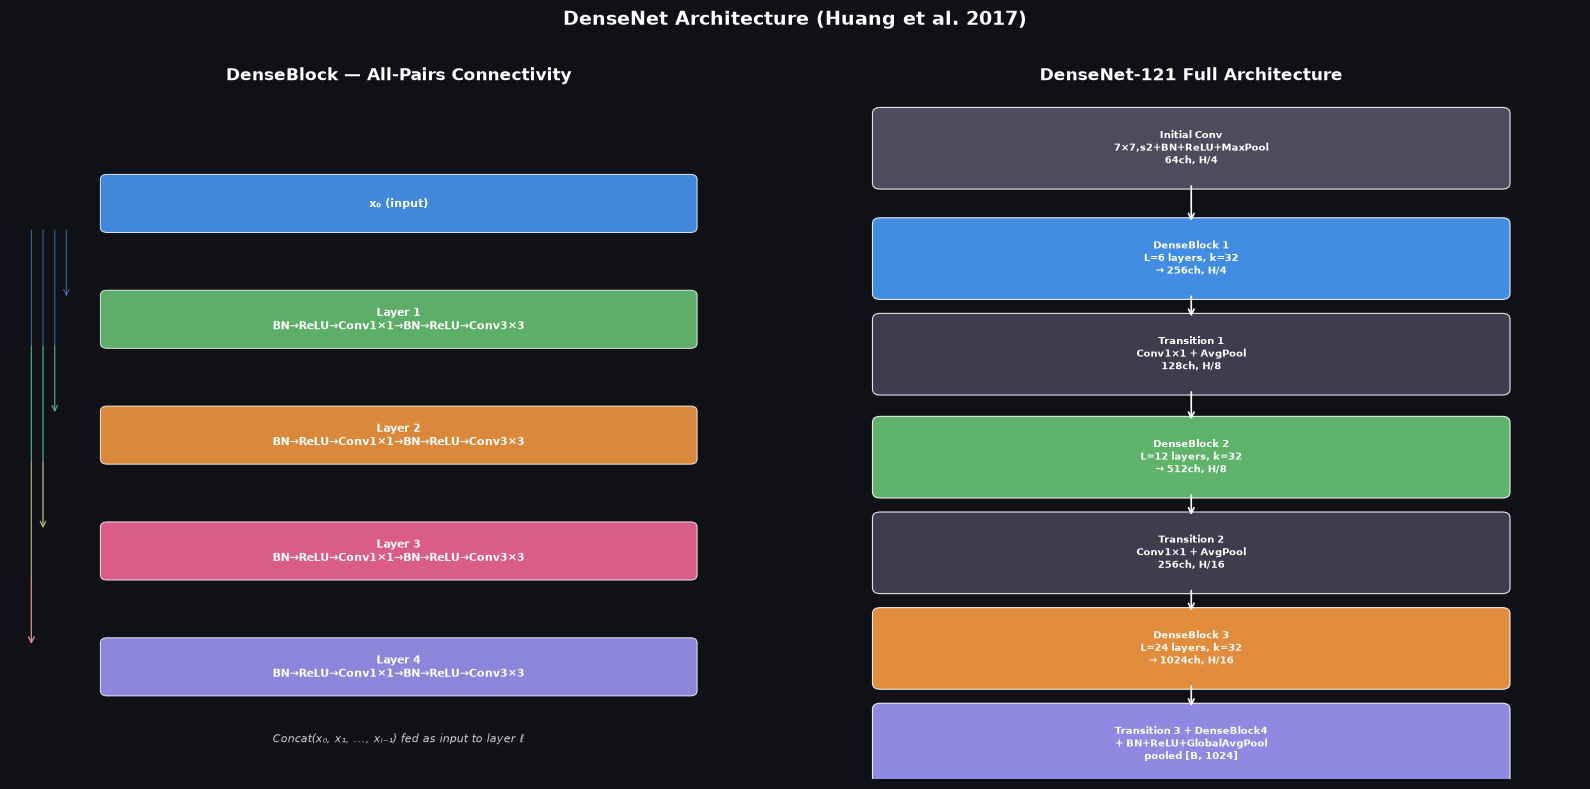

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
fig.patch.set_facecolor('#0f1117')

# ─── Left: DenseBlock internal connectivity ───
ax = axes[0]
ax.set_facecolor('#0f1117')
ax.set_xlim(0, 8); ax.set_ylim(0, 10); ax.axis('off')
ax.text(4, 9.5, 'DenseBlock — All-Pairs Connectivity', ha='center', color='white', fontsize=12, fontweight='bold')

n_layers = 5
layer_colors = ['#4a9eff', '#6bcb77', '#ff9f43', '#ff6b9d', '#a29bfe']
ys = np.linspace(7.8, 1.5, n_layers)

for i, (y, color) in enumerate(zip(ys, layer_colors)):
    label = 'x₀ (input)' if i == 0 else f'Layer {i}\nBN→ReLU→Conv1×1→BN→ReLU→Conv3×3'
    ax.add_patch(FancyBboxPatch((1.0, y - 0.3), 6.0, 0.65,
                                 boxstyle='round,pad=0.07', facecolor=color,
                                 edgecolor='white', linewidth=0.7, alpha=0.85))
    ax.text(4.0, y + 0.02, label, ha='center', va='center', color='white', fontsize=8, fontweight='bold')

# Draw dense connections: every prior layer feeds every subsequent layer
for src in range(n_layers - 1):
    for dst in range(src + 1, n_layers):
        x_offset = 0.7 - dst * 0.12
        color = layer_colors[src]
        ax.annotate('', xy=(x_offset, ys[dst] + 0.3), xytext=(x_offset, ys[src] - 0.3),
                    arrowprops=dict(arrowstyle='->', color=color, lw=0.8, alpha=0.6))

ax.text(4, 0.5, 'Concat(x₀, x₁, ..., xₗ₋₁) fed as input to layer ℓ',
        ha='center', color='#cccccc', fontsize=8, style='italic')

# ─── Right: Full DenseNet flow ───
ax2 = axes[1]
ax2.set_facecolor('#0f1117')
ax2.set_xlim(0, 8); ax2.set_ylim(0, 10); ax2.axis('off')
ax2.text(4, 9.5, 'DenseNet-121 Full Architecture', ha='center', color='white', fontsize=12, fontweight='bold')

blocks = [
    ('Initial Conv\n7×7,s2+BN+ReLU+MaxPool\n64ch, H/4', '#555566', 8.5),
    ('DenseBlock 1\nL=6 layers, k=32\n→ 256ch, H/4', '#4a9eff', 7.0),
    ('Transition 1\nConv1×1 + AvgPool\n128ch, H/8', '#444455', 5.7),
    ('DenseBlock 2\nL=12 layers, k=32\n→ 512ch, H/8', '#6bcb77', 4.3),
    ('Transition 2\nConv1×1 + AvgPool\n256ch, H/16', '#444455', 3.0),
    ('DenseBlock 3\nL=24 layers, k=32\n→ 1024ch, H/16', '#ff9f43', 1.7),
    ('Transition 3 + DenseBlock4\n+ BN+ReLU+GlobalAvgPool\npooled [B, 1024]', '#a29bfe', 0.4),
]

for label, color, cy in blocks:
    ax2.add_patch(FancyBboxPatch((0.8, cy - 0.4), 6.4, 0.95,
                                  boxstyle='round,pad=0.08', facecolor=color,
                                  edgecolor='white', linewidth=0.8, alpha=0.88))
    ax2.text(4.0, cy + 0.08, label, ha='center', va='center', color='white', fontsize=7.5, fontweight='bold')

for i in range(len(blocks) - 1):
    y1 = blocks[i][2] - 0.4
    y2 = blocks[i+1][2] + 0.55
    ax2.annotate('', xy=(4.0, y2), xytext=(4.0, y1),
                arrowprops=dict(arrowstyle='->', color='white', lw=1.2))

plt.suptitle('DenseNet Architecture (Huang et al. 2017)', color='white', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 3. Key ideas

## Key Innovations

### 1. Dense Connectivity
In a DenseBlock of $L$ layers, layer $ℓ$ receives input from all prior layers:
$$x_ℓ = H_ℓ([x_0, x_1, \ldots, x_{ℓ-1}])$$
where $[\cdot]$ denotes channel concatenation and $H_ℓ$ is BN→ReLU→Conv1×1→BN→ReLU→Conv3×3.

Total connections in a block: $\frac{L(L+1)}{2}$ vs $L$ in ResNet.

### 2. Growth Rate — Maximally Narrow Layers
Each layer adds only $k=32$ new channels (vs 64-256 in ResNet). This works because the growing concatenation already carries rich features. The total channels after $L$ layers:
$$C_L = C_0 + L \cdot k$$

### 3. Bottleneck for Efficiency
Each layer uses a 1×1 conv to compress the concatenated input to $4k$ channels before the 3×3 conv:
$$\text{DenseBottleneck: } \text{concat}(\cdot) \xrightarrow{\text{BN+ReLU+Conv1×1}} 4k \xrightarrow{\text{BN+ReLU+Conv3×3}} k$$

### 4. Compression via Transition Layers
Transition layers compress channels by $\theta=0.5$ and halve spatial resolution:
$$C_{out} = \lfloor \theta \cdot C_{in} \rfloor = C_{in} // 2$$

### 5. Feature Map Extraction for Dense Tasks
In this implementation, feature maps are captured BEFORE the Transition's AvgPool (at DenseBlock output resolution), providing multi-scale features compatible with FPN heads.

## Code Walkthrough

Implemented in `hale_core/nn/vision/cnn/densenet.py`.

**DenseBlock — concatenation accumulation:**
```python
class DenseBlock(nn.Module):
    def forward(self, x):
        features = [x]  # accumulate all outputs
        for layer in self.layers:
            new_feat = layer(torch.cat(features, dim=1))  # grows each call
            features.append(new_feat)
        return torch.cat(features, dim=1)  # full concatenated output
```

Memory note: the concatenation list grows to $L+1$ tensors per forward pass. For very deep blocks (L=64 in DenseNet-264), gradient checkpointing would reduce peak memory at the cost of recomputation.

**Transition — channel compression + spatial downsampling:**
```python
class _Transition(nn.Module):
    def __init__(self, in_ch, out_ch):  # out_ch = in_ch // 2
        self.norm = nn.BatchNorm2d(in_ch)
        self.conv = nn.Conv2d(in_ch, out_ch, kernel_size=1, bias=False)
        self.pool = nn.AvgPool2d(kernel_size=2, stride=2)
```

## 4. The architecture in pure PyTorch

Below is the **complete implementation** used by HaleBlocks (`hale_core/nn/vision/cnn/densenet.py`), one top-level
definition per cell, with its original comments and docstrings. Only the `hale_core` imports were replaced by the
two foundation cells (the `BackboneOutput` / `BaseVisionBackbone` contract and a 10-line registry), so this notebook
runs anywhere PyTorch is installed. §7 checks it is bit-for-bit the library implementation.

<details><summary>Module docstring of <code>cnn/densenet.py</code></summary>

```text
DenseNet Vision Backbones
=========================

Implements the DenseNet family (Huang et al. CVPR 2017, "Densely Connected
Convolutional Networks").

The key innovation: each layer is connected to ALL subsequent layers in its
dense block.  Instead of a single skip connection (ResNet), features are
concatenated — every layer has direct access to all prior feature maps,
maximising feature reuse and enabling very narrow layers (growth rate k=32)
to be competitive with much wider non-dense networks.

Architecture
------------
  Initial conv: Conv(3→2k, 7×7, s2, pad3) + BN + ReLU + MaxPool(3,s2)

  DenseBlock: each of L layers produces k new channels via:
    BN → ReLU → Conv1×1(in→4k) → BN → ReLU → Conv3×3(4k→k)
    Input to layer ℓ = concat of all prior layer outputs + initial input

  Transition: compresses and downsamples between blocks:
    BN → ReLU → Conv1×1(C→C//2) → AvgPool(2,s2)

  Four DenseBlocks separated by three Transitions, then:
    BN → ReLU → AdaptiveAvgPool → Linear → embed_dim

Feature map extraction: we return one feature map per DenseBlock output
(before the Transition's AvgPool), giving 4 spatial scales.

Registered names
----------------
  densenet121 — layers=(6,12,24,16), embed_dim=1024
  densenet169 — layers=(6,12,32,32), embed_dim=1664
  densenet201 — layers=(6,12,48,32), embed_dim=1920
  densenet264 — layers=(6,12,64,48), embed_dim=2688

Citation
--------
  Huang, G., Liu, Z., van der Maaten, L., & Weinberger, K. Q. (2017).
  Densely Connected Convolutional Networks. CVPR 2017. arXiv:1608.06993.
```
</details>

In [2]:
from __future__ import annotations

# Everything below is plain PyTorch - no hale_core import is needed to run this notebook.
import math
from abc import ABC, abstractmethod
from copy import deepcopy
from dataclasses import dataclass, field
from typing import Any, Callable, Optional, Type, TypeVar, Union

import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
print("torch", torch.__version__)

torch 2.14.1


### 4.1 Foundation: the backbone contract (`base.py`) and a local registry

In [3]:
@dataclass
class BackboneOutput:
    """Standard output container for all vision backbones.

    Attributes
    ----------
    pooled_output:
        Global image representation after spatial pooling. Shape [B, embed_dim].
        Used by: classification heads, VLM projectors, action encoders.

    patch_tokens:
        Per-patch (or per-pixel) feature tokens BEFORE pooling.
        Shape [B, N, embed_dim] for ViT-style; None for pure CNNs.
        Used by: VLM cross-attention, dense grounding.

    feature_maps:
        Multi-scale spatial feature tensors, ordered finest → coarsest.
        Each element: [B, C_i, H/s_i, W/s_i] where s_i is the stride.
        Used by: FPN, BEV encoder, depth heads.

    attentions:
        Optional list of attention weight tensors from each transformer block.
        Used for interpretability (attention rollout, DINO self-supervised heads).
    """

    pooled_output: torch.Tensor                          # [B, embed_dim]
    patch_tokens:  Optional[torch.Tensor] = None        # [B, N, D] or None
    feature_maps:  list[torch.Tensor] = field(default_factory=list)  # multi-scale
    attentions:    Optional[list[torch.Tensor]] = None  # transformer attention maps


class BaseVisionBackbone(ABC, nn.Module):
    """Abstract base for all vision backbones.

    Subclasses MUST define:
      - arch_name  (str): human-readable identifier, e.g. "resnet50"
      - embed_dim  (int): dimension of pooled_output
      - feature_dims (list[int]): channel counts for each feature map scale
      - forward(x) -> BackboneOutput

    Args:
        img_size:   Expected input spatial resolution (height == width assumed).
        in_chans:   Number of input image channels (default 3 for RGB).
        drop_rate:  Dropout probability applied to the final pooled features.
        out_indices: Which multi-scale feature stages to include in BackboneOutput.
                     E.g. [0, 1, 2, 3] returns all four scales; [2, 3] returns
                     only the two coarsest.  Default returns all available.
    """

    # ── Class-level metadata — override in each subclass ─────────────────────
    arch_name:    str        = "base"
    embed_dim:    int        = 0
    feature_dims: list[int] = []   # channel counts per stage, finest→coarsest

    def __init__(
        self,
        img_size:    int        = 224,
        in_chans:    int        = 3,
        drop_rate:   float      = 0.0,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__()
        self.img_size    = img_size
        self.in_chans    = in_chans
        self.drop_rate   = drop_rate
        self.out_indices = out_indices  # None = return all stages

    @abstractmethod
    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Run the backbone on a batch of images.

        Args:
            x: Float32 tensor of shape [B, in_chans, H, W].
               Typically ImageNet-normalised (mean=[0.485,0.456,0.406],
               std=[0.229,0.224,0.225]).

        Returns:
            BackboneOutput with pooled_output, patch_tokens, feature_maps.
        """
        ...

    # ── Convenience helpers ───────────────────────────────────────────────────

    def num_parameters(self, trainable_only: bool = False) -> int:
        """Count model parameters.

        Args:
            trainable_only: If True, count only parameters with requires_grad=True.

        Returns:
            Integer parameter count.
        """
        params = self.parameters()
        if trainable_only:
            params = (p for p in params if p.requires_grad)
        return sum(p.numel() for p in params)

    def freeze_all(self) -> None:
        """Freeze all parameters (no gradient computation).

        Useful when using the backbone as a frozen feature extractor
        inside a VLM or action decoder that only trains the head.
        """
        for p in self.parameters():
            p.requires_grad_(False)

    def unfreeze_all(self) -> None:
        """Unfreeze all parameters."""
        for p in self.parameters():
            p.requires_grad_(True)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze all stages from 0 up to and including `stage`.

        Useful for fine-tuning: freeze the early feature extractor stages
        and only fine-tune the later stages.  The exact meaning of "stage"
        is backbone-specific; see each subclass's docstring.

        Args:
            stage: Stage index (0-based).  Stages 0..stage are frozen.
        """
        raise NotImplementedError(
            f"{self.__class__.__name__} does not implement freeze_up_to_stage()"
        )

    def __repr__(self) -> str:
        return (
            f"{self.__class__.__name__}("
            f"arch={self.arch_name}, "
            f"embed_dim={self.embed_dim}, "
            f"img_size={self.img_size}, "
            f"params={self.num_parameters():,})"
        )

In [4]:
# A minimal stand-in for hale_core.nn.vision.registry: same decorator name and behaviour, so the
# library source below runs unchanged. Re-registration is allowed so cells can be re-run.
_VISION_BACKBONES: dict[str, type] = {}
T = TypeVar("T")


def register_vision_backbone(name: str) -> Callable[[T], T]:
    """Class decorator: store ``cls`` under ``name`` (lower-case)."""
    def decorator(cls: T) -> T:
        _VISION_BACKBONES[name.lower()] = cls
        return cls
    return decorator


def build_vision_backbone(name: str, **kwargs: Any) -> "BaseVisionBackbone":
    """Instantiate a backbone registered in this notebook."""
    return _VISION_BACKBONES[name.lower()](**kwargs)


def list_vision_backbones() -> list[str]:
    return sorted(_VISION_BACKBONES)

### 4.2 `cnn/densenet.py`, definition by definition

**`_DenseLayer`** - Single layer in a DenseBlock.

In [5]:
class _DenseLayer(nn.Module):
    """Single layer in a DenseBlock.

    Implements the BN-ReLU-Conv1×1-BN-ReLU-Conv3×3 "bottleneck" design.
    Input is ALL prior layer outputs concatenated; output is k new channels.

    The 1×1 conv compresses the accumulated channels to 4k before the 3×3 conv,
    keeping computation tractable as the concatenation dimension grows.

    Args:
        num_input_features: Number of input channels (all prior features).
        growth_rate:        k — number of new channels this layer produces.
        memory_efficient:   Use gradient checkpointing (not implemented here).
    """
    def __init__(self, num_input_features: int, growth_rate: int) -> None:
        super().__init__()
        inter_ch = 4 * growth_rate  # 1×1 conv target = 4k

        self.norm1 = nn.BatchNorm2d(num_input_features)
        self.conv1 = nn.Conv2d(num_input_features, inter_ch, kernel_size=1, bias=False)
        self.norm2 = nn.BatchNorm2d(inter_ch)
        self.conv2 = nn.Conv2d(inter_ch, growth_rate, kernel_size=3, padding=1, bias=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Typical implementation receives a list of all previous outputs which
        # are concatenated inside forward — this matches DenseNet paper appendix.
        out = self.conv1(F.relu(self.norm1(x), inplace=True))
        out = self.conv2(F.relu(self.norm2(out), inplace=True))
        return out

**`DenseBlock`** - Dense block: L layers with all-pairs skip connections.

In [6]:
class DenseBlock(nn.Module):
    """Dense block: L layers with all-pairs skip connections.

    Each layer's input is the concatenation of ALL previous layer outputs
    plus the block's initial input.  This means layer ℓ has
    in_ch + ℓ * growth_rate input channels.

    Args:
        num_layers:          L — number of dense layers.
        num_input_features:  Channels at block entry.
        growth_rate:         k — channels added per layer.
    """
    def __init__(self, num_layers: int, num_input_features: int, growth_rate: int) -> None:
        super().__init__()
        self.layers = nn.ModuleList()
        for i in range(num_layers):
            self.layers.append(_DenseLayer(
                num_input_features=num_input_features + i * growth_rate,
                growth_rate=growth_rate,
            ))
        # Channels after this block
        self.out_channels = num_input_features + num_layers * growth_rate

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Accumulate all feature maps in a list and concat for each new layer
        features = [x]
        for layer in self.layers:
            new_feat = layer(torch.cat(features, dim=1))
            features.append(new_feat)
        return torch.cat(features, dim=1)  # [B, num_input + L*k, H, W]

**`_Transition`** - Transition layer between DenseBlocks.

In [7]:
class _Transition(nn.Module):
    """Transition layer between DenseBlocks.

    Halves both channel count (via 1×1 conv) and spatial resolution (AvgPool).
    The compression factor of 0.5 is fixed per the original paper (θ=0.5).

    Args:
        num_input_features:  Input channels (= DenseBlock output channels).
        num_output_features: Output channels (= num_input_features // 2).
    """
    def __init__(self, num_input_features: int, num_output_features: int) -> None:
        super().__init__()
        self.norm = nn.BatchNorm2d(num_input_features)
        self.conv = nn.Conv2d(num_input_features, num_output_features, kernel_size=1, bias=False)
        self.pool = nn.AvgPool2d(kernel_size=2, stride=2)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.pool(self.conv(F.relu(self.norm(x), inplace=True)))

**`DenseNet`** - Generic DenseNet backbone.

In [8]:
class DenseNet(BaseVisionBackbone):
    """Generic DenseNet backbone.

    Returns 4 multi-scale feature maps (one per DenseBlock output, before Transition
    pooling) plus a global pooled embedding after the final block.

    Args:
        block_config:  Number of layers per DenseBlock, e.g. (6, 12, 24, 16).
        growth_rate:   k — channels added per dense layer (default 32).
        init_features: Channels after initial conv (= 2*k = 64).
        img_size:      Input resolution.
        in_chans:      Input channels.
        drop_rate:     Dropout after global pooling.
    """

    def __init__(
        self,
        block_config:  tuple[int, ...],
        growth_rate:   int   = 32,
        init_features: int   = 64,
        img_size:      int   = 224,
        in_chans:      int   = 3,
        drop_rate:     float = 0.0,
        **kwargs,
    ) -> None:
        super().__init__(img_size=img_size, in_chans=in_chans, drop_rate=drop_rate)

        k = growth_rate

        # Initial convolution: 3 → 2k channels, stride-2 + MaxPool stride-2
        self.initial = nn.Sequential(
            nn.Conv2d(in_chans, init_features, kernel_size=7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(init_features),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
        )

        num_features = init_features
        self.dense_blocks: nn.ModuleList = nn.ModuleList()
        self.transitions:  nn.ModuleList = nn.ModuleList()
        feature_dims: list[int] = []

        for i, num_layers in enumerate(block_config):
            block = DenseBlock(
                num_layers=num_layers,
                num_input_features=num_features,
                growth_rate=k,
            )
            self.dense_blocks.append(block)
            num_features = block.out_channels
            feature_dims.append(num_features)

            if i != len(block_config) - 1:
                # Transition compresses channels by 0.5 and halves spatial resolution
                out_ch = num_features // 2
                trans = _Transition(num_features, out_ch)
                self.transitions.append(trans)
                num_features = out_ch
            else:
                # No transition after the last block
                self.transitions.append(None)  # placeholder for indexing consistency

        # Final BN before pooling
        self.final_norm = nn.BatchNorm2d(num_features)
        self.pool       = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout    = nn.Dropout(drop_rate) if drop_rate > 0.0 else nn.Identity()

        self.embed_dim    = num_features
        self.feature_dims = feature_dims  # channels after each DenseBlock (before transition pool)

        self._init_weights()

    def _init_weights(self) -> None:
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x: torch.Tensor) -> BackboneOutput:
        x = self.initial(x)  # [B, init_features, H/4, W/4]

        feature_maps = []
        for i, (block, trans) in enumerate(zip(self.dense_blocks, self.transitions)):
            x = block(x)
            # Capture feature map BEFORE transition's AvgPool for FPN compatibility
            feature_maps.append(x)

            if trans is not None:
                x = trans(x)  # halves spatial + channel dims

        # Final normalisation and global pooling
        x = F.relu(self.final_norm(x), inplace=True)
        pooled = self.dropout(self.pool(x).flatten(1))  # [B, embed_dim]

        if self.out_indices is not None:
            feature_maps = [feature_maps[i] for i in self.out_indices]

        return BackboneOutput(
            pooled_output=pooled,
            patch_tokens=None,
            feature_maps=feature_maps,
            attentions=None,
        )

    def freeze_up_to_stage(self, stage: int) -> None:
        if stage < 0 or stage >= len(self.dense_blocks):
            raise ValueError(f"stage must be in [0, {len(self.dense_blocks)-1}], got {stage}")
        # Freeze initial stem
        for p in self.initial.parameters():
            p.requires_grad_(False)
        for i in range(stage + 1):
            for p in self.dense_blocks[i].parameters():
                p.requires_grad_(False)
            if self.transitions[i] is not None:
                for p in self.transitions[i].parameters():
                    p.requires_grad_(False)

**`DenseNet121`** - DenseNet-121: (6,12,24,16) layers, k=32, embed_dim=1024.

In [9]:
@register_vision_backbone("densenet121")
class DenseNet121(DenseNet):
    """DenseNet-121: (6,12,24,16) layers, k=32, embed_dim=1024."""
    arch_name = "densenet121"
    embed_dim = 1024
    feature_dims = [256, 512, 1024, 1024]

    def __init__(self, **kwargs):
        super().__init__(block_config=(6, 12, 24, 16), growth_rate=32, init_features=64, **kwargs)

**`DenseNet169`** - DenseNet-169: (6,12,32,32) layers, k=32, embed_dim=1664.

In [10]:
@register_vision_backbone("densenet169")
class DenseNet169(DenseNet):
    """DenseNet-169: (6,12,32,32) layers, k=32, embed_dim=1664."""
    arch_name = "densenet169"
    embed_dim = 1664
    feature_dims = [256, 512, 1280, 1664]

    def __init__(self, **kwargs):
        super().__init__(block_config=(6, 12, 32, 32), growth_rate=32, init_features=64, **kwargs)

**`DenseNet201`** - DenseNet-201: (6,12,48,32) layers, k=32, embed_dim=1920.

In [11]:
@register_vision_backbone("densenet201")
class DenseNet201(DenseNet):
    """DenseNet-201: (6,12,48,32) layers, k=32, embed_dim=1920."""
    arch_name = "densenet201"
    embed_dim = 1920
    feature_dims = [256, 512, 1792, 1920]

    def __init__(self, **kwargs):
        super().__init__(block_config=(6, 12, 48, 32), growth_rate=32, init_features=64, **kwargs)

**`DenseNet264`** - DenseNet-264: (6,12,64,48) layers, k=32, embed_dim=2688.

In [12]:
@register_vision_backbone("densenet264")
class DenseNet264(DenseNet):
    """DenseNet-264: (6,12,64,48) layers, k=32, embed_dim=2688."""
    arch_name = "densenet264"
    embed_dim = 2688
    feature_dims = [256, 512, 2112, 2688]

    def __init__(self, **kwargs):
        super().__init__(block_config=(6, 12, 64, 48), growth_rate=32, init_features=64, **kwargs)

## 5. Build and run it

Every variant defined above is now in the notebook's registry. Build the demo variants, run a batch through them and
check the `BackboneOutput` contract: `pooled_output (B, embed_dim)`, multi-scale `feature_maps` (finest → coarsest)
and, for transformers, `patch_tokens`. The **stride** of each map is `input size / map size`.

In [13]:
DEMOS = {"densenet121": 8.0}          # variant -> paper parameter count (M, incl. 1000-class head)
IMG = 224
print("variants defined in this notebook:", list_vision_backbones())

x = torch.randn(2, 3, IMG, IMG)
models = {}
for name in DEMOS:
    torch.manual_seed(0)
    model = build_vision_backbone(name, img_size=IMG).eval()
    models[name] = model
    with torch.no_grad():
        out = model(x)
    print(f"\n{name}  ({type(model).__name__})")
    print(f"  pooled_output : {tuple(out.pooled_output.shape)}   embed_dim = {model.embed_dim}")
    if out.patch_tokens is not None:
        print(f"  patch_tokens  : {tuple(out.patch_tokens.shape)}")
    for i, fm in enumerate(out.feature_maps):
        print(f"  feature_map {i}: {tuple(fm.shape)}   stride {IMG / fm.shape[-1]:.0f}")
    assert out.pooled_output.shape == (2, model.embed_dim)

variants defined in this notebook: ['densenet121', 'densenet169', 'densenet201', 'densenet264']

densenet121  (DenseNet121)
  pooled_output : (2, 1024)   embed_dim = 1024
  feature_map 0: (2, 256, 56, 56)   stride 4
  feature_map 1: (2, 512, 28, 28)   stride 8
  feature_map 2: (2, 1024, 14, 14)   stride 16
  feature_map 3: (2, 1024, 7, 7)   stride 32


## 6. Parameter count vs the paper

Papers report parameters *including* the 1000-class classifier; the backbone has none, so `+ head` adds
`embed_dim × 1000 + 1000`. ✅ = within 5 % of the paper.

In [14]:
print(f"{'variant':20s} {'backbone':>10s} {'+ head':>10s} {'paper':>8s} {'ratio':>7s}")
for name, paper in DEMOS.items():
    model = models[name]
    p = sum(t.numel() for t in model.parameters()) / 1e6
    with_head = p + (model.embed_dim * 1000 + 1000) / 1e6
    if paper is None:
        print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {'n/a':>8s}")
        continue
    ratio = with_head / paper
    print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {paper:7.1f}M {ratio:7.2f}  {'✅' if abs(ratio - 1) < 0.05 else '⚠️ differs from paper'}")

variant                backbone     + head    paper   ratio
densenet121               6.95M      7.98M     8.0M    1.00  ✅


### Gradient flow

A backbone is only useful if every parameter is trained. Back-propagate a scalar through the pooled output **and**
all feature maps and list parameters that receive no gradient.

In [15]:
for name, model in models.items():
    model.train().zero_grad()
    out = model(torch.randn(2, 3, IMG, IMG))
    loss = out.pooled_output.square().mean() + sum(fm.square().mean() for fm in out.feature_maps)
    loss.backward()
    dead = [n for n, p in model.named_parameters() if p.requires_grad and (p.grad is None or not torch.isfinite(p.grad).all())]
    total = sum(1 for p in model.parameters() if p.requires_grad)
    print(f"{name}: loss {loss.item():.4f} | {total - len(dead)}/{total} parameter tensors receive a finite gradient")
    if dead:
        print("   no gradient:", dead[:8], "..." if len(dead) > 8 else "")
    model.eval()

densenet121: loss 12.1479 | 362/362 parameter tensors receive a finite gradient


## 7. Same code as the library?

If `hale_core` (HaleBlocks) is installed, build the library model, copy this notebook's weights into it with
`strict=True` (same parameter names and shapes) and compare outputs. A difference of `0.0` proves the code above *is*
the library implementation. Without HaleBlocks installed the check is skipped - the notebook itself is unaffected.

In [16]:
try:
    import logging, importlib
    logging.disable(logging.CRITICAL)
    try:
        from loguru import logger as _lg; _lg.remove()
    except ImportError:
        pass
    from hale_core.nn.vision.registry import build_vision_backbone as build_library_backbone
except ImportError:
    build_library_backbone = None
    print("hale_core is not installed here - skipping the library equivalence check.")

if build_library_backbone is not None:
    for name, model in models.items():
        lib = build_library_backbone(name, img_size=IMG).eval()
        lib.load_state_dict(model.state_dict(), strict=True)
        with torch.no_grad():
            a, b = model(x), lib(x)
        diff = max([(a.pooled_output - b.pooled_output).abs().max().item()] +
                   [(fa - fb).abs().max().item() for fa, fb in zip(a.feature_maps, b.feature_maps)])
        print(f"{name}: notebook vs hale_core max |diff| = {diff:.1e}  {'✅ identical' if diff == 0 else ''}")

densenet121: notebook vs hale_core max |diff| = 0.0e+00  ✅ identical


## 8. What the feature maps look like

A synthetic image (a few coloured shapes) through the first demo variant: the channel-mean activation of every
feature map. Early maps keep edges at high resolution, late maps are coarse and semantic.

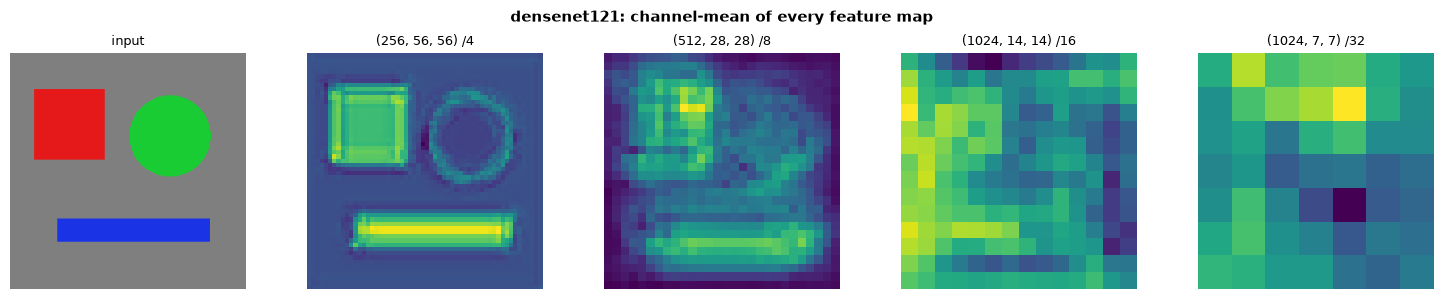

In [17]:
import matplotlib.pyplot as plt

def synthetic_image(size: int) -> torch.Tensor:
    """(1, 3, size, size) image with a red square, a green disc and a blue bar on grey."""
    yy, xx = torch.meshgrid(torch.linspace(0, 1, size), torch.linspace(0, 1, size), indexing="ij")
    img = torch.full((3, size, size), 0.5)
    sq = (xx > 0.1) & (xx < 0.4) & (yy > 0.15) & (yy < 0.45)
    disc = (xx - 0.68) ** 2 + (yy - 0.35) ** 2 < 0.03
    bar = (xx > 0.2) & (xx < 0.85) & (yy > 0.7) & (yy < 0.8)
    for mask, rgb in ((sq, (0.9, 0.1, 0.1)), (disc, (0.1, 0.8, 0.2)), (bar, (0.1, 0.2, 0.9))):
        for c in range(3):
            img[c][mask] = rgb[c]
    mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    return ((img - mean) / std)[None], img

name = next(iter(models))
inp, raw = synthetic_image(IMG)
with torch.no_grad():
    maps = models[name](inp).feature_maps
fig, axes = plt.subplots(1, len(maps) + 1, figsize=(3 * (len(maps) + 1), 3), facecolor="white")
axes[0].imshow(raw.permute(1, 2, 0)); axes[0].set_title("input", fontsize=9)
for ax, fm in zip(axes[1:], maps):
    ax.imshow(fm[0].mean(0), cmap="viridis")
    ax.set_title(f"{tuple(fm.shape[1:])} /{IMG // fm.shape[-1]}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.suptitle(f"{name}: channel-mean of every feature map", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

## 9. Experiments from the original walkthrough

The original notebook's hands-on cells, now running on the implementation defined in §4 (they used to import
`hale_core` through a relative `sys.path`, which only worked inside the HaleBlocks repo).

In [18]:
import sys
import numpy as np
import matplotlib.pyplot as plt

In [19]:
import torch
import sys


for name in ['densenet121', 'densenet169', 'densenet201']:
    bb = build_vision_backbone(name, img_size=224)
    bb.eval()
    x = torch.randn(1, 3, 224, 224)
    with torch.no_grad():
        out = bb(x)
    fmaps = [tuple(f.shape) for f in out.feature_maps]
    print(f'{name}:')
    print(f'  pooled:       {tuple(out.pooled_output.shape)}')
    print(f'  feature_maps: {fmaps}')
    print(f'  params:       {bb.num_parameters()/1e6:.1f}M')
    print()

densenet121:
  pooled:       (1, 1024)
  feature_maps: [(1, 256, 56, 56), (1, 512, 28, 28), (1, 1024, 14, 14), (1, 1024, 7, 7)]
  params:       7.0M



densenet169:
  pooled:       (1, 1664)
  feature_maps: [(1, 256, 56, 56), (1, 512, 28, 28), (1, 1280, 14, 14), (1, 1664, 7, 7)]
  params:       12.5M



densenet201:
  pooled:       (1, 1920)
  feature_maps: [(1, 256, 56, 56), (1, 512, 28, 28), (1, 1792, 14, 14), (1, 1920, 7, 7)]
  params:       18.1M



## References

| Paper | Venue | Key Contribution |
|-------|-------|------------------|
| Huang et al. (2017). Densely Connected CNNs. | CVPR 2017 (Best Paper) | DenseNet — all-pairs skip connections |
| He et al. (2016). Deep Residual Learning. | CVPR 2016 | ResNet — single skip connection predecessor |
| Srivastava et al. (2015). Highway Networks. | NeurIPS 2015 | Gated skip connections |
| Huang et al. (2016). Deep Networks with Stochastic Depth. | ECCV 2016 | Stochastic depth (same group) |
| Pleiss et al. (2017). Memory-Efficient Implementation of DenseNets. | arXiv 2017 | Gradient checkpointing for DenseBlocks |

**Full Citation:**
> Huang, G., Liu, Z., van der Maaten, L., & Weinberger, K. Q. (2017). Densely connected convolutional networks. In *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition* (pp. 4700–4708). arXiv:1608.06993.